In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
from dotenv import load_dotenv, find_dotenv
from supabase import create_client

load_dotenv(find_dotenv(usecwd=True))
client = create_client(os.getenv("SUPABASE_URL"), os.getenv("SUPABASE_ANON_KEY"))


def load_table(name, page=1000):
    rows, start = [], 0
    while True:
        chunk = client.table(name).select("*").range(start, start + page - 1).execute().data
        rows.extend(chunk)
        if len(chunk) < page:
            break
        start += page
    return pd.DataFrame(rows)


repos = load_table("repos")
events = load_table("events")
commits = load_table("commits")
prs = load_table("pull_requests")
issues = load_table("issues")

for name, df in [("repos", repos), ("events", events), ("commits", commits),
                 ("prs", prs), ("issues", issues)]:
    print(name, df.shape)

repos (23, 8)
events (10482, 6)
commits (14547, 5)
prs (6107, 10)
issues (3978, 10)


In [4]:
commits.head()

,sha,repo_id,author_login,author_name,committed_at
0,a7292b4f26e37f59ba12d670e53d8806d5c2527f,28457823,majestic-owl448,majestic-owl448,2026-11-05T12:56:03+00:00
1,721afe66f9e83f95ab18d89349f49b4795264d70,28457823,majestic-owl448,majestic-owl448,2026-11-05T12:54:24+00:00
2,fd4891280a7c0251157d6708249119ebd7f7a41b,28457823,Supravisor,Supravisor,2026-11-05T12:34:02+00:00
3,fdc1020b6143845d653302d53434a6bbec19fd0e,28457823,majestic-owl448,majestic-owl448,2026-11-04T21:12:52+00:00
4,a80abfd6b08619626fe100513bf83a156fd20108,28457823,majestic-owl448,majestic-owl448,2026-11-04T21:04:12+00:00


In [9]:
prs.head()

,id,repo_id,number,title,state,user_login,created_at,updated_at,closed_at,merged_at
0,5187136134,594155488,8797,Combine Processor and Editor theme providers,open,jbrunton96,2026-11-06T11:28:15+00:00,2026-11-06T11:29:00+00:00,NaN,NaN
1,5153300840,594155488,8771,Enterprise procurement page,open,reecebrowne,2026-11-04T11:19:19+00:00,2026-11-06T11:28:54+00:00,NaN,NaN
2,5186887082,594155488,8796,Add server-provided fonts to the PDF text editor,open,Frooodle,2026-11-06T11:06:38+00:00,2026-11-06T11:14:39+00:00,NaN,NaN
3,5086313395,594155488,8726,fix(security): support non-ASCII characters in...,open,Aniket29110,2026-10-30T14:53:48+00:00,2026-11-06T09:23:09+00:00,NaN,NaN
4,4810154121,594155488,8433,Refine Italian translations,closed,albanobattistella,2026-10-10T09:19:36+00:00,2026-11-06T07:43:06+00:00,2026-11-06T07:43:06+00:00,NaN


In [5]:
commits.info()

<class 'pandas.DataFrame'>
RangeIndex: 14326 entries, 0 to 14325
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype
---  ------        --------------  -----
 0   sha           14326 non-null  str  
 1   repo_id       14326 non-null  int64
 2   author_login  14318 non-null  str  
 3   author_name   14326 non-null  str  
 4   committed_at  14326 non-null  str  
dtypes: int64(1), str(4)
memory usage: 1.8 MB


In [6]:
repos[["full_name", "language", "stars"]]

,full_name,language,stars
0,freeCodeCamp/freeCodeCamp,TypeScript,458610
1,morluto/rea,TypeScript,434015
2,react/react,JavaScript,252013
3,nextlevelbuilder/ui-ux-pro-max-skill,Python,145680
4,vercel/next.js,JavaScript,143340
5,shadcn-ui/ui,TypeScript,127437
6,fastapi/fastapi,Python,104454
7,django/django,Python,91542
8,spring-projects/spring-boot,Java,81740
9,headroomlabs-ai/headroom,Python,78928


In [ ]:
for df, col in [(events, "created_at"), (commits, "committed_at"),
                (prs, "created_at"), (issues, "created_at")]:
    df[col] = pd.to_datetime(df[col], utc=True)

names = repos.set_index("id")["full_name"]
for df in (events, commits, prs, issues):
    df["repo"] = df["repo_id"].map(names)

In [8]:
commits.info()

<class 'pandas.DataFrame'>
RangeIndex: 14326 entries, 0 to 14325
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype              
---  ------        --------------  -----              
 0   sha           14326 non-null  str                
 1   repo_id       14326 non-null  int64              
 2   author_login  14318 non-null  str                
 3   author_name   14326 non-null  str                
 4   committed_at  14326 non-null  datetime64[us, UTC]
 5   repo          14326 non-null  str                
dtypes: datetime64[us, UTC](1), int64(1), str(4)
memory usage: 1.8 MB


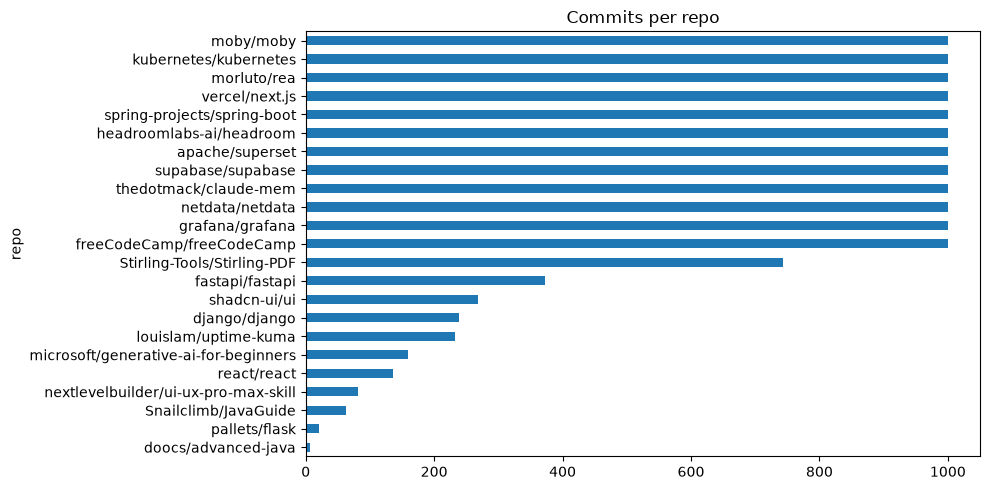

In [12]:
commits["repo"].value_counts().sort_values().plot(
    kind="barh", figsize=(10, 5), title="Commits per repo"
)
plt.tight_layout()
plt.show()

In [13]:
cap_check = commits.groupby("repo")["committed_at"].agg(["count", "min", "max"])
cap_check.sort_values("count", ascending=False)

,count,min,max
repo,,,
vercel/next.js,1000,2026-09-15 14:26:34+00:00,2026-11-05 20:13:25+00:00
grafana/grafana,1000,2026-10-19 15:22:40+00:00,2026-11-05 21:28:29+00:00
supabase/supabase,1000,2026-09-24 05:50:39+00:00,2026-11-05 21:30:40+00:00
netdata/netdata,1000,2026-08-10 11:47:05+00:00,2026-11-05 21:33:43+00:00
morluto/rea,1000,2026-10-26 08:11:09+00:00,2026-11-05 20:27:31+00:00
moby/moby,1000,2024-07-30 21:28:58+00:00,2026-11-05 20:18:25+00:00
kubernetes/kubernetes,1000,2024-02-06 18:17:57+00:00,2026-11-05 21:03:30+00:00
headroomlabs-ai/headroom,1000,2026-08-14 02:12:38+00:00,2026-11-05 19:33:39+00:00
freeCodeCamp/freeCodeCamp,1000,2026-08-18 15:44:09+00:00,2026-11-05 12:56:03+00:00


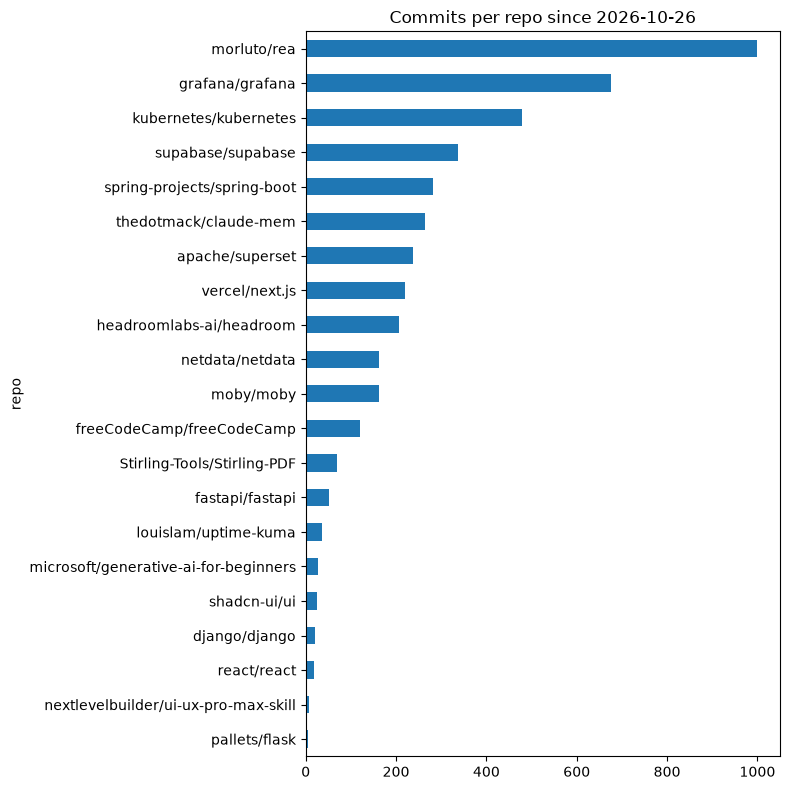

In [14]:
start = cap_check["min"].max()
fair = commits[commits["committed_at"] >= start]
fair["repo"].value_counts().sort_values().plot(
    kind="barh", figsize=(8, 8), title=f"Commits per repo since {start.date()}"
)
plt.tight_layout()
plt.show()